### Lab 3 - Boost Converters

In this lab you will study a **boost converter**. This is a device that boosts a DC voltage from a low level to a high level. These devices are very common both in the power grid, and in electronics to change voltage levels. In this lab, the low level is 5V, and the high level is 12V. Not only do we need to provide a 12V DC supply, but the voltage level should be steady (not fluctuating) and it should be exactly 12V, not just close. Even when the load that the DC to DC converter is connected to changes (like a motor is turned on/off for example) we still need a constant 12V being supplied. This means that we need a controller to regulate the output voltage. In other words we need a robust controller, even though the load is changing (i.e. the system dynamics are changing), we still need the output to stay at 12V (our reference signal in this case is a constant signal of 12V).

In this lab you will:
- learn about boost converters, 
- implement and tune a proportional controller,
- learn about the advantages of integral action and implement a PI controller

### Boost Converters

The circuit diagram of a boost converter is shown below. I will provide a very brief sketch of how boost converters work. If you are interested in power electronics, there is a fourth year technical elective, ENEL585, dedicated only to these types of circuits! 

![Boost Converter](boost.png "Boost Converter")

Compare this circuit diagram to the PCB in the lab:

![](BoostReal.png)

In the diagram $Z_L$ represents the load that the Boost converter is connected to. This could be a circuit that it is powering. In this lab, the load will simply consist of some resistors (a resistive load). Up to five resistors can be switched into the load using switches. The circuit is shown below.

![](loadBankReal.png)

In this circuit you can think of the MOSFET as simply a switch. This means that the boost converter has two topologies, toplogogy 1 when the switch is open: 

![Boost Open](boostStage2.png "Boost open")

And topology 2 when the switch is closed:

![Boost closed](boostStage1.png "Boost closed")

When the switch is closed, there is a short circuit between left side of the diode and ground, which means that no current will flow through the diode in this state (it essentially turns into an open circuit).

The objective of this circuit is to boost the input voltage $v_s(t)$ to a higher output voltage $v_c(t)$. Losely speaking, the circuit operates as follows:

1. Suppose that the switch is closed, so the circuit is in topology 2. A magnetic field will be built up in the  inductor, thus "storing current". 
2. As soon as the switch closes, the "stored current" in the inductor rushes into the capacitor. 
3. Because of the inrush of current, the stored energy in the capacitor increases, which means that the voltage across the capacitor increases. 
4. The switch opens again quickly before the magnetic field in the inductor has completely collapsed. 
5. The cycle repeats.

Loosely speaking, the inductor is building up "pressure" when the switch is closed, releasing the pressure to "squirt" current into the capacitor when the switch opens, closing the switch again quickly before the "pressure" drops too much, and then repeating this cycle. The net effect is that the voltage on the capacitor is "pumped" up to a level higher than the voltage source $v_s$. 

The level to which the voltage is pumped depends directly on the switching frequency. The more "pressure" that you build up, the higher you can push the output voltage. This means that the switch needs to be closed for most of the cycle time. 

When the switch is closed, the capacitor will be slowly discharging, especially when the boost converter is connected to a load, the load will de drawing power. So the switch has to open and close fast enough keep pumping current into the capacitor (typical switching frequencies are 5-50kHz). 

A pulse width modulated (PWM) signal is used to drive the gate of the MOSFET (i.e. open and close the switch). This is a square wave signal, where the *duty cycle* of the PWM signal can be changed. The dudty cycle represents the ratio of how long the *high* portion of the square wave is compared to the *low* portion. As described, this will directly affect the value of the output voltage of the boost converter. 

In the code below change the duty cycle to see how the PWM signal changes. 

Text(0.5, 1.0, 'Signal applied to MOSFET Gate')

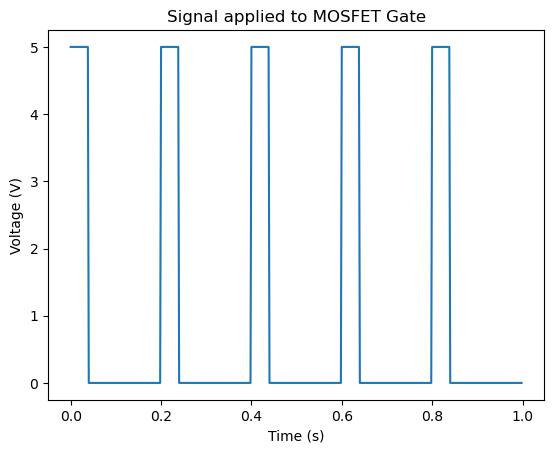

In [2]:
import scipy as sp
import numpy as np
import matplotlib.pyplot as plt

duty_cycle = 0.2 # change the duty cycle of the PWM signal to see the effect. 

t = np.linspace(0, 1, 500, endpoint=False)
d = sp.signal.square(2*np.pi*5*t, duty=0.2)
d = (d+1)*2.5
fig,ax = plt.subplots(1)
ax.plot(t,d)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Voltage (V)')
ax.set_title('Signal applied to MOSFET Gate')


The key point is that the duty cycle of the PWM signal affects the output voltage. Now, let's think about control systems. We want the output voltage to be as steady as possible (in this lab we want it to be 12V). The load resistance $Z_L$ will be changing all the time (you will be able to add/remove resistance by flipping the switches on the load bank circuit board). But even under these variations, we still need the output to be exactly 12 V. This is exactly what a controller can do! 

The feedback loop:
1. Measure the voltage $v_c(t)$.
2. If it is too low, increase the duty cycle of the PWM, if it is too high, decrease the duty cycle of the PWN. This is a controller!

The feedback diagram is shown below:

![Boost closed loop](boostClosedloop.png "Boost closed loop")

### Closed loop diagram

We can represent the circuit with controller as a block diagram shown below. 

![block diagram](blockDiagram.JPG "block diagram")

Where:
- $r$ is the reference, and equal to a constant signal of $12$ V, 
- $d$ is the input to the circuit and is the duty cycle of the PWM signal,
- $v_C$ is the output and is the voltage across the load $Z_L$. 

Notice how the block diagram is an abstraction of the physical circuit.

### Sensors

To implement the feedback control loop shown above, you need to measure the voltage $v_c$ since this is the voltage that must be regulated, i.e. controlled. How do we do this? 

The Arduino comes with a analog to digital converter (ADC), however, it can only accept voltages between 0 and 5V (the operating range of an Arduino). So we need to design a circuit that draws minimal power, and scales the output $v_c$ which can be in the range 0-20V to the range 0-5V. 

We can use a voltage divider to do this. We have to choose large values for the resistors to ensure the voltage divider draw minimal current. However, we cannot directly connect a high impedance circuit to an Arduino (which is a low impedance circuit) because it will draw too much power from the Arduino. So we use a voltage follower to connect the output of the voltage divider to the Arduino ADC pin. Recall that a voltage follower has high input resistance, and low output resistance, but the input voltage is equal to the output voltage. 

The combined voltage divider and voltage follower circuit is shown below.

![voltage divider and follower](voltageDividerOpAmp.JPG "voltage divider and follower")

You can see this circuitry on the ENEL441 voltage divider plugged into the Arduino:

![](voltageDividerReal.png)

### Actuators

The second component that we need to build a control loop is a way to actuate the system (the input to the plant). In this case the Boost converter plus the load is the plant, and the input is the PWM signal. This signal allows us to change the output of the plant (the voltage across the load). The Arduino can generate PWM signals with varying duty cycles. So this is the input of our system.  

### Open Loop

First you will investigate the system in open loop in order to understand how the input (PWM duty cycle) affects the output (DC voltage accross the capacitor).

### Setup Steps
1. While connecting the circuit make sure the power supply is off.
2. Connect the input of the boost converter to the 5V power supply using banana plugs.
4. Turn on the power supply, but keep the terminals off (don't apply 5V to the circuit yet).
5. Set the voltage limit on the power supply to 5V.
6. Set the current limit to 2A.
7. Open the file 'arduino_voltage_scope.py'. This code is used to connect to the Arduino, and plot the measured output voltage.
8. Scroll to the beginning of the file. Here are some constants that you need to change.
9. Type in your com port number in the variable 'com_port'.
10. Set open_or_closed_loop to 0 (for open loop behavior).
11. Set the input u=0. This means a step input with constant duty cycle of 10/255 will be applied to the circuit. 
12. Set all the switches in the load bank to the right.
13. Turn on the terminals of the power supply to apply 5V to the circuit.
14. Run the program 'arduino_voltage_scope.py'. You can run the program from VS Code for example. A figure should pop up showing the output voltage.

### Watch the current

During the lab, keep an eye on the current being drawn by the circuit. Although all components are rated to handle up to 2A or current, at no point during this lab, should it actually draw more than 0.5A. If you notice that the current is more than 0.5A, please check all your wire connections, or call over a TA to investigate if the situation persists. 

### The Experiment

1. Notice the transient response of the system when the step input is applied. 
2. Record the final output value of the open loop step response. You just need to record the number (you can zoom in on the plot to get an accurate reading).
3. Close the figure (this ends the program).
4. Enter a new value for the step input: set u=10.
5. Run the program 'arduino_voltage_scope.py'.
6. Repeat steps 1-5 for u=0,10,20,30,40,50,60,70,80,90,100.
7. Make a plot of the input duty cycle vs output voltage.

This plot gives you an idea how changing the duty cycle of the PWM signal affects the output voltage. Isn't it cool that we can boost the output voltage of the circuit? What is the minimum voltage that we can supply at the output of the boost converter? In this case the maximum output voltage is 20V (I have put a Zener diode at the output terminal that saturates at 20V in order to protect the circuitry connected to the output of the boost converter). 

# Answer

Min voltage occurs when duty = 10/255 and 4.58V is the minimum.

Text(0, 0.5, 'Output Voltage (V)')

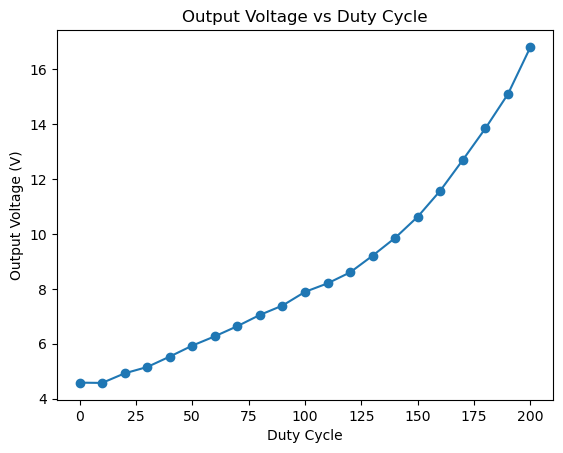

In [5]:
### your code here

duty_cycles = [duty for duty in range(0,201,10)]
output_voltages = [4.58, 4.57, 4.92, 5.15, 5.53, 5.93, 6.27, 6.64, 7.05, 7.39, 7.89, 8.20, 8.60, 9.21, 9.86, 10.63, 11.58, 12.70, 13.85, 15.1, 16.82]

fig, ax = plt.subplots(1)
ax.plot(duty_cycles, output_voltages, marker='o')
ax.set_title('Output Voltage vs Duty Cycle')
ax.set_xlabel('Duty Cycle')
ax.set_ylabel('Output Voltage (V)')

Determine what the duty cycle should be in order to supply 12V to the load. 

In [8]:
### your calculations here
Slope =   (170-160) / (12.70-11.58)


duty_cycle = 160 + Slope*(12-11.58) 

print(duty_cycle)

163.75


Set the duty cycle to this value. Run the scope and check that your calculations are correct. You don't need a perfect 12V in this case. Just within a volt. Now start closing the switches in the load bank (you are removing resistors, i.e. reducing the resistance of the load). What happens to the output voltage? Hint: it should change. How much does the output voltage change? In terms of a power supply it is not a nice property that the output voltage changes when the load changes! We need to incorporate a controller to ensure that the voltage is held steady at 12V. 

# Answer

Our duty cycle produced a result of 12.02V. 

One switch closed = +0.3V

Two switch closed = +0.57V

Three switch closed = +2.78V

Four switch closed = +7.6V

Five switch closed = +8V


### TA Check

Show the TA's your plot, and that your circuit is working properly. 

### Closed Loop - Proportional Control

Now we want the output voltage to be a constant 12V. 

However, the load $Z_L$ changes when the switches in the load bank are turned on/off. No matter what the load is, we want the output voltage of the system to be 12V. So we need a controller to keep the output at 12V. In this case we need a very robust controller. The load is part of the plant in this case, and the load keeps changing. So the dynamics of the plant keep changing, but we want the output of the plant to be 12V, no matter what the load is. 

We will start with a proportional controller.

1. In the file 'arduino_voltage_scope.py' set open_or_closed_loop to 1 (for closed loop behavior). The reference signal in this case is hardcoded to 12V on the Arduino.
2. Set the proportional gain Kp=10. Keep the integral gain set to zero for now.
3. Run the program 'arduino_voltage_scope.py'. 
4. Notice the transient response of the system when the controller is turned on. How does the output voltage change when the load changes? Does it remain constant at 12V as desired? Set all the switches to the on position (to the right). Slowly close each switch. Note the (closed loop) response of the output voltage. What is the voltage difference from all switches open to all switches closed? Record this number. Is the voltage ever exactly 12V?
5. Repeat steps 1-4 for Kp=50,100,150,200,250,300. 

Make a plot of the voltage range (all switches open to all switches closed) vs proportional gain. Does this plot match the theory of proportional control that we studied in class? How so (i.e. what is the effect of increasing gain on steady state error)? Back up your answer with equations.  

Kp = [10, 50, 100, 150, 200, 250, 300]

Open = [9.21, 11.01, 11.31, 11.51, 11.88, 11.88, 11.85]

Close = [19.6, 13.72, 13.07, 12.56, 12.36, 12.32, 12.29] 

The V is never exactly 12V, but gets close on either side (within 0.5V).

Text(0, 0.5, 'Output Voltage (V)')

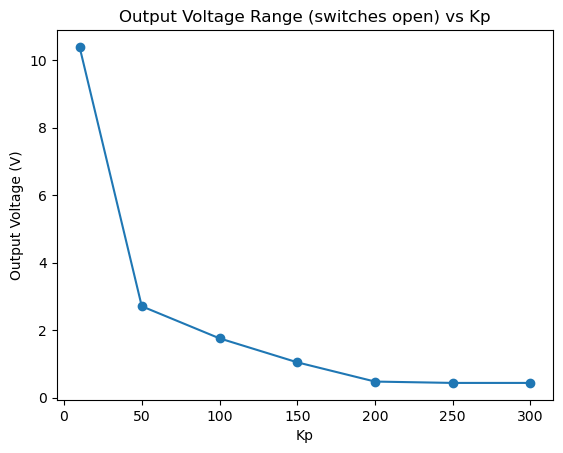

In [ ]:
Kp = [10, 50, 100, 150, 200, 250, 300]
Open = np.array([9.21, 11.01, 11.31, 11.51, 11.88, 11.88, 11.85])
Close = np.array([19.6, 13.72, 13.07, 12.56, 12.36, 12.32, 12.29])
Range = np.subtract(Close, Open)


fig, ax = plt.subplots(1)
ax.plot(Kp, Range, marker='o')
ax.set_title('Error (switches open) vs Kp')
ax.set_xlabel('Kp')
ax.set_ylabel('Error (V)')

As Kp increases the difference between open and close switches decreases. If we assume the switches changing is disturbance, the change to the output from disturbance will be propotional to the sensitivity function (S). As $K_p$ increases, S decreases and the disturbance rejection increases.

$S=\frac{1}{1+K_{P}\cdot P}$

### Closed loop - PI control

You should have noticed that the output in the previous experiment never reached exactly 12V as desired. For this application, it is important that the output is exactly 12V. 

To fix this situation, we will add integral action to our controller. 

The output of the controller will now be:

$$
u(t) = K_p \varepsilon(t) + K_i \int_{o}^t \varepsilon(\tau)d\tau,
$$
where the $K_p$ term is the proportional term and the $K_i$ term is a new term with integral action.

### Question

What is the output of the integral term when there is a steady state error? In other words, plot the output of the integral term $K_i \int_{o}^t \varepsilon(\tau)d\tau$ when $\varepsilon(t) = c$, where $c$ is some (small) constant?
$$

Text(0, 0.5, 'Steady State Error')

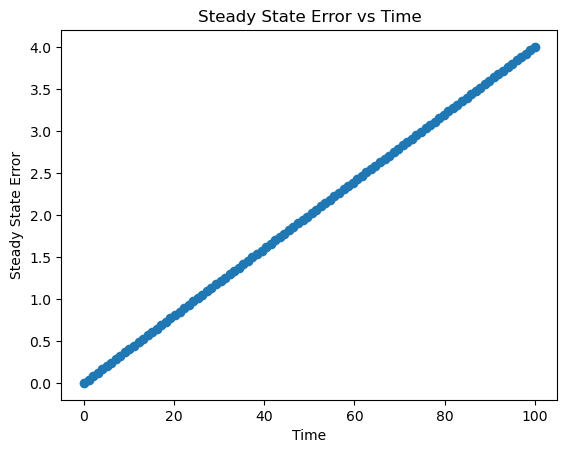

In [15]:
### you code here

t = np.linspace(0,100,100)
c = 0.002

Ki = 20

result = t * c * Ki

fig, ax = plt.subplots(1)
ax.plot(t, result, marker='o')
ax.set_title('Steady State Error vs Time')
ax.set_xlabel('Time')
ax.set_ylabel('Steady State Error')

What do you notice about the integral term? In words, what will it do when there is a steady state error?

# Answer

The integral term is a linear line.

It will linearly increase or decrease (depending on sign of error) when there is a steady state error

### Adding Integral Action

So let's add integral action to our setup. 

1. Leave the proportional gain at 300. Set Ki=1
2. Run the program 'arduino_voltage_scope.py'. 
3. Notice the transient response of the system when the controller is turned on. What is the steady state voltage? Record this number. How does the output voltage change when the load changes? Move all the switches from the on position to the off position. Does the output remain constant at 12V as desired?
4. Repeat steps 1-4 for Ki=2,3,4,5. For each new value of the integral gain note how the output voltage is changing. 

# Answer

There was essentially no error and it remained at a steady 12V. There are some frequent pulses when zooming into the signal, but overall, the result averages out to a clean 12V. Disturbances from switches, do not change this result.

Text(0, 0.5, 'Error (V)')

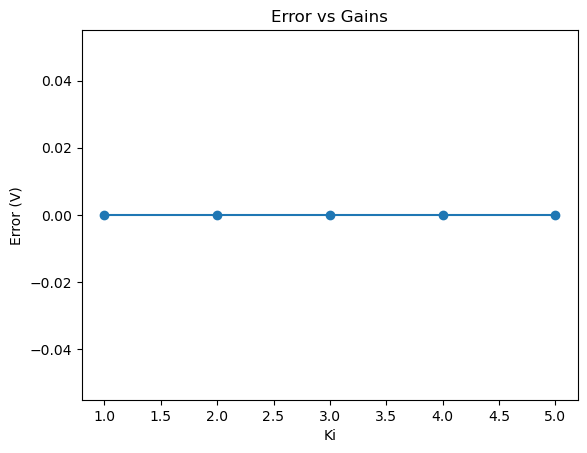

In [23]:
ki = [1, 2, 3, 4, 5]  
error = [0, 0, 0, 0, 0]


fig, ax = plt.subplots(1)
line = ax.plot(ki, error, marker='o')

ax.set_title('Error vs Gains')
ax.set_xlabel('Ki')
ax.set_ylabel('Error (V)')

Make a plot of the steady state error. Compare this plot to the one obtained earlier for the proportional controller. What is different?

# Answer

Compared to the proportional, there is essentially no change in the error as it remains close to zero through all tests with $K_i$ increasing. In the proportional, there was a decrease as $K_p$ increased, which is not seen here.

### Question

How did the integral action affect the steady state error? Why? Provide a reasoning based on your earlier calculations.

# Answer

After the $K_p$ term moves the output to a steady state, the steady state error moved towards zero as a result of the integral term. The term accumulates magnitude according to the presence of error, so that the steady state error is accounted for in the controller and goes to zero. 

Based on earlier calculations, it was shown that the integral term linearly increases or decreases in the presence of the error, this allows it to account for steady state error. 

### Question

Let the plant be equal to $P(s) = \frac{B(s)}{A(s)}$. The Laplace transform of an integral is $\frac{1}{s}$. Thus the transfer function for a PI controller is $K(s) = K_p + K_i \frac{1}{s}$. Using the same methodology as we did in class, calculate the steady state error to a step function when the controller is a PI controller. What do your calculations tell you? Does this match what you observed in this lab?

# Answer

At low frequency, $\frac{1}{s}\cdot K_{i}$ leads since it is large at low frequency and is very large causeing the overall error to be smaller. At high frequency this term is small, and $K_p$ leads as in a proportional controller. This was seen in the lab as $K_i$ adjusts to steady state error which is very low frequency, matching our conclusion about frequency responses from $K_i$.

$\varepsilon\ =\ \frac{A}{A+\left(K_{p}+\frac{1}{s}\cdot K_{i}\right)\cdot B}\cdot\frac{1}{s}$

For this setup, this is about as good as we can get for the voltage regulator. In order to get a really stable response, the frequency of the PWM and of the controller on the Arduino could be increased. Industrial and commercial voltage regulators run at speeds of up to 50kHz. This circuit is running at 4000Hz. Loosely speaking, the increase in switching speed will increase the responsiveness of the system, flattening out the last few "bumps" in the output voltage.

### END OF LAB